# HMDA 2024 – Data Preparation (Pandas)

Downloads the HMDA 2024 One-Year National LAR, converts it to Parquet, and prepares the S0/S1/S2 analysis samples with Pandas, applying the shared rules in `rules.py`.

- **Input:** HMDA 2024 One-Year CSV (4.4 GB) → `raw.parquet` (12,259,199 rows, 99 columns)
- **Outputs:** `raw.parquet`, `rules.py`, `clean_pandas/` (S0, S1, S2, partitioned by `state_code`), `audit_pandas/`
- Section 1 uses Spark once to convert the CSV to Parquet; Sections 2–5 use Pandas.
- All cells have already been run; outputs are kept for reference.

## 1. Data Collection (run once – do NOT re-run)

In [ ]:
!wget -O /content/hmda2024.zip https://files.ffiec.cfpb.gov/static-data/one-year/2024/2024_public_lar_one_year_csv.zip
!unzip -o /content/hmda2024.zip -d /content/hmda
!ls -lh /content/hmda

--2026-11-12 02:41:45--  https://files.ffiec.cfpb.gov/static-data/one-year/2024/2024_public_lar_one_year_csv.zip
Resolving files.ffiec.cfpb.gov (files.ffiec.cfpb.gov)... 23.7.56.110, 2600:1408:ec00:108e::31d7, 2600:1408:ec00:1089::31d7
Connecting to files.ffiec.cfpb.gov (files.ffiec.cfpb.gov)|23.7.56.110|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 666476625 (636M) [application/zip]
Saving to: ‘/content/hmda2024.zip’

/content/hmda2024.z 100%[===================>] 635.60M  56.4MB/s    in 13s     

2026-11-12 02:41:59 (47.1 MB/s) - ‘/content/hmda2024.zip’ saved [666476625/666476625]

Archive:  /content/hmda2024.zip
  inflating: /content/hmda/2024_public_lar_one_year_csv.csv  
total 4.4G
-rw-rw-r-- 1 root root 4.4G Jun  2 22:21 2024_public_lar_one_year_csv.csv


In [ ]:
!pip install pyspark -q
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
BASE = "/content/drive/MyDrive/hmda/"
os.makedirs(BASE, exist_ok=True)

from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName("HMDA2024")
         .config("spark.driver.memory", "10g")
         .getOrCreate())
spark

In [ ]:
CSV_PATH = "/content/hmda/2024_public_lar_one_year_csv.csv"

raw = spark.read.csv(CSV_PATH, header=True, inferSchema=False)
print("Columns:", len(raw.columns))
print(raw.columns)

Columns: 99
['activity_year', 'lei', 'derived_msa_md', 'state_code', 'county_code', 'census_tract', 'conforming_loan_limit', 'derived_loan_product_type', 'derived_dwelling_category', 'derived_ethnicity', 'derived_race', 'derived_sex', 'action_taken', 'purchaser_type', 'preapproval', 'loan_type', 'loan_purpose', 'lien_status', 'reverse_mortgage', 'open_end_line_of_credit', 'business_or_commercial_purpose', 'loan_amount', 'combined_loan_to_value_ratio', 'interest_rate', 'rate_spread', 'hoepa_status', 'total_loan_costs', 'total_points_and_fees', 'origination_charges', 'discount_points', 'lender_credits', 'loan_term', 'prepayment_penalty_term', 'intro_rate_period', 'negative_amortization', 'interest_only_payment', 'balloon_payment', 'other_nonamortizing_features', 'property_value', 'construction_method', 'occupancy_type', 'manufactured_home_secured_property_type', 'manufactured_home_land_property_interest', 'total_units', 'multifamily_affordable_units', 'income', 'debt_to_income_ratio', 'a

In [ ]:
LOCAL_PQ = "/content/parquet/raw.parquet"
raw.write.mode("overwrite").parquet(LOCAL_PQ)

In [ ]:
df = spark.read.parquet(LOCAL_PQ)
print("Rows:", df.count())

!du -sh /content/parquet/raw.parquet
!cp -r /content/parquet/raw.parquet /content/drive/MyDrive/hmda/
!ls -lh /content/drive/MyDrive/hmda/

Rows: 12259199
522M	/content/parquet/raw.parquet
total 4.0K
drwx------ 2 root root 4.0K Nov 12 02:56 raw.parquet


## 2. Data Understanding

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/parquet
!cp -rn /content/drive/MyDrive/hmda/raw.parquet /content/parquet/

import os, time
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt

BASE  = "/content/drive/MyDrive/hmda/"
AUDIT = BASE + "audit_pandas/"
os.makedirs(AUDIT, exist_ok=True)
RAW = "/content/parquet/raw.parquet"

KEEP = [
    # Outcome
    "action_taken",
    # Financial
    "income", "debt_to_income_ratio", "loan_amount",
    "combined_loan_to_value_ratio", "property_value",
    # Loan
    "loan_type", "loan_purpose", "lien_status", "occupancy_type",
    "derived_loan_product_type", "construction_method",
    # Applicant
    "applicant_age", "derived_race", "derived_ethnicity", "derived_sex",
    # Denial
    "denial_reason_1", "denial_reason_2", "denial_reason_3", "denial_reason_4",
    # Context
    "state_code", "county_code", "census_tract", "lei",

    "tract_population", "tract_minority_population_percent",
    "ffiec_msa_md_median_family_income", "tract_to_msa_income_percentage",
    "tract_owner_occupied_units", "tract_one_to_four_family_homes",
    "tract_median_age_of_housing_units",
]

dset = ds.dataset(RAW, format="parquet")
all_cols = dset.schema.names
print("Original columns:", len(all_cols))
print("Columns not found:", [c for c in KEEP if c not in all_cols])

t0 = time.time()
df = dset.to_table(columns=KEEP).to_pandas(strings_to_categorical=True)
load_time = time.time() - t0

total = len(df)
print(f"Load xong trong {load_time:.1f}s")
print(f"Rows: {total:,} | Columns: {df.shape[1]}")
print(f"RAM used: {df.memory_usage(deep=True).sum()/1e9:.2f} GB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
Original columns: 99
Columns not found: []
Load xong trong 43.2s
Rows: 12,259,199 | Columns: 31
RAM used: 0.63 GB


In [ ]:
df.info(memory_usage="deep")
df.head(3).T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12259199 entries, 0 to 12259198
Data columns (total 31 columns):
 #   Column                             Dtype   
---  ------                             -----   
 0   action_taken                       category
 1   income                             category
 2   debt_to_income_ratio               category
 3   loan_amount                        category
 4   combined_loan_to_value_ratio       category
 5   property_value                     category
 6   loan_type                          category
 7   loan_purpose                       category
 8   lien_status                        category
 9   occupancy_type                     category
 10  derived_loan_product_type          category
 11  construction_method                category
 12  applicant_age                      category
 13  derived_race                       category
 14  derived_ethnicity                  category
 15  derived_sex                        category
 16

,0,1,2
action_taken,6,6,6
income,NA,NA,NA
debt_to_income_ratio,NA,NA,NA
loan_amount,275000,315000,705000
combined_loan_to_value_ratio,NA,NA,NA
property_value,325000,325000,775000
loan_type,2,2,1
loan_purpose,1,1,1
lien_status,1,1,1
occupancy_type,1,1,1


In [ ]:
CODES = ["NA", "Exempt", "1111", "8888"]

rows = []
for c in df.columns:
    s = df[c]
    row = {"column": c, "null": int(s.isna().sum() + (s == "").sum())}
    for k in CODES:
        row[k] = int((s == k).sum())
    rows.append(row)

miss = pd.DataFrame(rows)
miss["pct_special"] = (miss[["null"] + CODES].sum(axis=1) / total * 100).round(2)
miss = miss.sort_values("pct_special", ascending=False).reset_index(drop=True)
miss.to_csv(AUDIT + "2c_missing_special_codes.csv", index=False)
miss

,column,null,NA,Exempt,1111,8888,pct_special
0,denial_reason_4,12243362,0,0,0,0,99.87
1,denial_reason_3,12171698,0,0,0,0,99.29
2,denial_reason_2,11789224,0,0,0,0,96.17
3,debt_to_income_ratio,0,4060236,287240,0,0,35.46
4,combined_loan_to_value_ratio,0,4030609,287538,0,0,35.22
5,property_value,0,2455474,288601,0,0,22.38
6,income,0,1780434,0,77,11,14.52
7,applicant_age,0,0,0,0,1463684,11.94
8,census_tract,0,349023,0,0,0,2.85
9,county_code,0,296190,0,0,0,2.42


In [ ]:
dup = int(df.duplicated().sum())
print(f"Duplicate rows: {dup:,} ({dup/total*100:.3f}%)")

Duplicate rows: 71,299 (0.582%)


In [ ]:
ACTION_LABELS = {"1": "Originated", "2": "Approved not accepted", "3": "Denied",
                 "4": "Withdrawn", "5": "Incomplete", "6": "Purchased",
                 "7": "Preapproval denied", "8": "Preapproval approved not accepted"}

def freq(c, n=30):
    t = df[c].value_counts(dropna=False).head(n).rename_axis(c).reset_index(name="count")
    t["share_%"] = (t["count"] / total * 100).round(2)
    return t

act = freq("action_taken")
act["label"] = act["action_taken"].astype(str).map(ACTION_LABELS)
act.to_csv(AUDIT + "2e_action_taken.csv", index=False)
display(act)

n1 = int((df["action_taken"] == "1").sum())
n3 = int((df["action_taken"] == "3").sum())
print(f"Originated: {n1:,} | Denied: {n3:,}")
print(f"Baseline denial rate = denied / (originated + denied) = {n3/(n1+n3)*100:.2f}%")

,action_taken,count,share_%,label
0,1,6197085,50.55,Originated
1,3,2103462,17.16,Denied
2,4,1538273,12.55,Withdrawn
3,6,1276504,10.41,Purchased
4,5,581940,4.75,Incomplete
5,2,361232,2.95,Approved not accepted
6,8,153391,1.25,Preapproval approved not accepted
7,7,47312,0.39,Preapproval denied


Originated: 6,197,085 | Denied: 2,103,462
Baseline denial rate = denied / (originated + denied) = 25.34%


In [ ]:
CAT_COLS = ["loan_type", "loan_purpose", "lien_status", "occupancy_type",
            "derived_loan_product_type", "construction_method",
            "debt_to_income_ratio", "applicant_age", "derived_sex",
            "denial_reason_1"]

for c in CAT_COLS:
    t = freq(c)
    t.to_csv(AUDIT + f"2e_{c}.csv", index=False)
    print(f"\n=== {c} ===")
    display(t)


=== loan_type ===


,loan_type,count,share_%
0,1,9291143,75.79
1,2,1873873,15.29
2,3,1018511,8.31
3,4,75672,0.62



=== loan_purpose ===


,loan_purpose,count,share_%
0,1,6577902,53.66
1,32,1737013,14.17
2,4,1397909,11.40
3,31,1320403,10.77
4,2,1205589,9.83
5,5,20383,0.17



=== lien_status ===


,lien_status,count,share_%
0,1,9401786,76.69
1,2,2857413,23.31


... (10 outputs left out)


=== derived_sex ===


,derived_sex,count,share_%
0,Male,3796183,30.97
1,Joint,3736592,30.48
2,Female,2501726,20.41
3,Sex Not Available,2224698,18.15



=== denial_reason_1 ===


,denial_reason_1,count,share_%
0,10,9890479,80.68
1,1,694446,5.66
2,3,578555,4.72
3,4,269897,2.20
4,7,256080,2.09
5,1111,247789,2.02
6,9,163738,1.34
7,6,83896,0.68
8,5,52127,0.43
9,2,21690,0.18


In [ ]:
def to_num(s):
    """Convert a category column to numeric; NA/Exempt -> NaN."""
    if isinstance(s.dtype, pd.CategoricalDtype):
        cats = pd.to_numeric(pd.Series(s.cat.categories.astype(str)), errors="coerce").to_numpy()
        vals = np.append(cats, np.nan)   # code -1 (missing) -> NaN
        return pd.Series(vals[s.cat.codes.to_numpy()], index=s.index, dtype="float64")
    return pd.to_numeric(s, errors="coerce")

NUM_COLS = ["income", "loan_amount", "combined_loan_to_value_ratio", "property_value",
            "tract_to_msa_income_percentage", "ffiec_msa_md_median_family_income"]

num = pd.DataFrame({c: to_num(df[c]) for c in NUM_COLS})

num_summary = num.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2)
num_summary.to_csv(AUDIT + "2f_numeric_summary.csv")
num_summary

,count,mean,std,min,1%,25%,50%,75%,99%,max
income,10478765.0,320.73,337722.59,-155317.0,0.00,67.00,104.00,165.00,836.00,1.000000e+09
loan_amount,12259199.0,315308.73,3020228.65,5000.0,15000.00,105000.00,225000.00,375000.00,1445000.00,2.962005e+09
combined_loan_to_value_ratio,7941052.0,2602.68,4220743.10,0.0,9.46,60.12,79.14,92.97,104.88,1.093680e+10
property_value,9515124.0,541459.82,3964808.92,5000.0,65000.00,255000.00,385000.00,585000.00,2505000.00,2.147484e+09
tract_to_msa_income_percentage,12259199.0,106.63,43.69,0.0,0.00,81.00,103.00,129.00,238.00,5.160000e+02
ffiec_msa_md_median_family_income,12259199.0,97815.84,26115.11,0.0,0.00,85300.00,98000.00,109800.00,164200.00,2.013000e+05


In [ ]:
checks = {
    "income_le_0":         (num["income"] <= 0).sum(),
    "loan_amount_le_0":    (num["loan_amount"] <= 0).sum(),
    "cltv_gt_250":         (num["combined_loan_to_value_ratio"] > 250).sum(),
    "property_value_le_0": (num["property_value"] <= 0).sum(),
}
implaus = pd.DataFrame([{"rule": k, "rows": int(v), "pct": round(v/total*100, 3)}
                        for k, v in checks.items()])
implaus.to_csv(AUDIT + "2f_implausible_values.csv", index=False)
implaus

,rule,rows,pct
0,income_le_0,165254,1.348
1,loan_amount_le_0,0,0.000
2,cltv_gt_250,3680,0.030
3,property_value_le_0,0,0.000


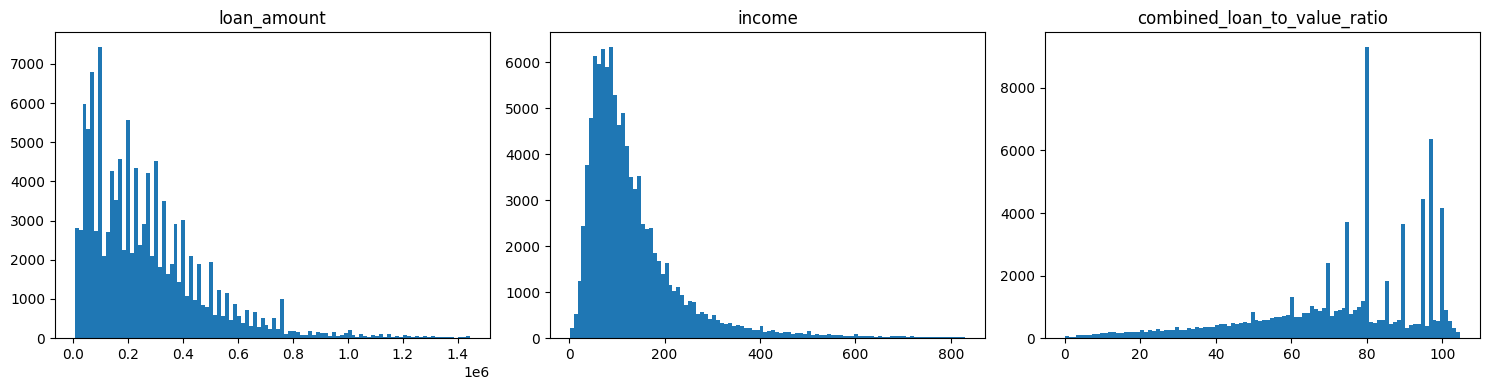

In [ ]:
sample = num.sample(frac=0.01, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["loan_amount", "income", "combined_loan_to_value_ratio"]):
    s = sample[c].dropna()
    s = s[(s > 0) & (s <= s.quantile(0.99))]
    ax.hist(s, bins=100)
    ax.set_title(c)
plt.tight_layout()
plt.savefig(AUDIT + "2g_distributions.png", dpi=120)
plt.show()

In [ ]:
print(f"Load time (Pandas): {load_time:.1f}s")
print(f"Total rows: {total:,}")
print(f"Columns kept: {df.shape[1]} / {len(all_cols)}")
print(f"Duplicate rows: {dup:,} ({dup/total*100:.3f}%)")
print(f"Baseline denial rate: {n3/(n1+n3)*100:.2f}%")
print("\nTop 10 columns by missing/special values:")
print(miss.head(10)[["column", "pct_special"]].to_string(index=False))
print("\nImplausible values:")
print(implaus.to_string(index=False))

Load time (Pandas): 48.7s
Total rows: 12,259,199
Columns kept: 31 / 99
Duplicate rows: 71,299 (0.582%)
Baseline denial rate: 25.34%

Top 10 columns by missing/special values:
                      column  pct_special
             denial_reason_4        99.87
             denial_reason_3        99.29
             denial_reason_2        96.17
        debt_to_income_ratio        35.46
combined_loan_to_value_ratio        35.22
              property_value        22.38
                      income        14.52
               applicant_age        11.94
                census_tract         2.85
                 county_code         2.42

Implausible values:
               rule   rows   pct
        income_le_0 165254 1.348
   loan_amount_le_0      0 0.000
        cltv_gt_250   3680 0.030
property_value_le_0      0 0.000


## 3. Data Cleaning (creates the shared rules.py)

In [ ]:
%%writefile /content/drive/MyDrive/hmda/rules.py
"""
Shared cleaning & feature-engineering rules – HMDA 2024 (Group 6)
Shared by Pandas and PySpark. Contains constants and mapping tables only.
"""

# ---------- 1. Missing / special codes ----------
MISSING_STRINGS = ["", "NA", "Exempt"]   # -> missing in every column
EXEMPT_CODE = "1111"                      # -> missing, CODE_COLS only
AGE_NA_CODE = "8888"                      # -> missing, AGE_COLS only

CODE_COLS = ["action_taken", "loan_type", "loan_purpose", "lien_status",
             "occupancy_type", "construction_method",
             "denial_reason_1", "denial_reason_2", "denial_reason_3", "denial_reason_4"]
AGE_COLS = ["applicant_age"]

# ---------- 2. Data types ----------
NUMERIC_COLS = ["income", "loan_amount", "combined_loan_to_value_ratio", "property_value",
                "tract_population", "tract_minority_population_percent",
                "ffiec_msa_md_median_family_income", "tract_to_msa_income_percentage",
                "tract_owner_occupied_units", "tract_one_to_four_family_homes",
                "tract_median_age_of_housing_units"]
# All other columns stay as string/category (codes and IDs: state_code, county_code, census_tract, lei)

# ---------- 3. Implausible values: set to missing + flag, do NOT drop rows ----------
IMPLAUSIBLE = {
    "income": ("le", 0),                          # income <= 0
    "combined_loan_to_value_ratio": ("gt", 250),  # CLTV > 250%
}

# ---------- 4. Duplicate rows ----------
DUPLICATE_ACTION = "flag"   # flag only, do not drop (HMDA has no application ID)

# ---------- 5. Outcome & samples ----------
ORIGINATED = "1"
DENIED = "3"
S1_CODES = ["1", "3"]       # originated & denied
S2_CODES = ["3"]            # denied only
# Denial rate = denied / (originated + denied)

# ---------- 6. Feature engineering ----------
INCOME_UNIT = 1000          # income in thousands of USD; loan_amount in USD

DTI_BAND_MAP = {"<20%": "<20%", "20%-<30%": "20-<30%", "30%-<36%": "30-<36%",
                "50%-60%": "50-60%", ">60%": ">60%"}
DTI_BAND_MAP.update({str(v): "36-43%" for v in range(36, 44)})
DTI_BAND_MAP.update({str(v): "44-49%" for v in range(44, 50)})
DTI_BAND_ORDER = ["<20%", "20-<30%", "30-<36%", "36-43%", "44-49%", "50-60%", ">60%"]

# CLTV: RIGHT-CLOSED intervals (a, b]  -> PySpark uses when(col <= b), NOT Bucketizer [a, b)
CLTV_UPPER = [60, 80, 90, 95, 100, 250]
CLTV_BAND_ORDER = ["<=60", "60-80", "80-90", "90-95", "95-100", "100-250"]

# ---------- 7. Leakage guard (never used in models) ----------
LEAKAGE_COLS = ["denial_reason_1", "denial_reason_2", "denial_reason_3", "denial_reason_4",
                "interest_rate", "rate_spread", "total_loan_costs", "origination_charges",
                "discount_points", "lender_credits", "purchaser_type", "hoepa_status",
                "total_points_and_fees"]

Writing /content/drive/MyDrive/hmda/rules.py


In [ ]:
import sys, importlib
sys.path.insert(0, BASE)
import rules
importlib.reload(rules)

def to_num(s):
    if isinstance(s.dtype, pd.CategoricalDtype):
        cats = pd.to_numeric(pd.Series(s.cat.categories.astype(str)), errors="coerce").to_numpy()
        vals = np.append(cats, np.nan)
        return pd.Series(vals[s.cat.codes.to_numpy()], index=s.index, dtype="float64")
    return pd.to_numeric(s, errors="coerce")

log = []
def add_log(step, column, rows, action):
    log.append({"step": step, "column": column, "rows": int(rows), "action": action})

t_clean = time.time()
clean = df.copy()

In [ ]:
for c in clean.columns:
    s = clean[c]
    mask = s.isin(rules.MISSING_STRINGS)
    if c in rules.CODE_COLS:
        mask |= (s == rules.EXEMPT_CODE)
    if c in rules.AGE_COLS:
        mask |= (s == rules.AGE_NA_CODE)
    n = int(mask.sum())
    if n:
        clean[c] = s.mask(mask)
        if isinstance(clean[c].dtype, pd.CategoricalDtype):
            clean[c] = clean[c].cat.remove_unused_categories()
        add_log("3.2 missing codes", c, n, "NA/Exempt/1111/8888 -> NaN")

pd.DataFrame(log)

,step,column,rows,action
0,3.2 missing codes,income,1780434,NA/Exempt/1111/8888 -> NaN
1,3.2 missing codes,debt_to_income_ratio,4347476,NA/Exempt/1111/8888 -> NaN
2,3.2 missing codes,combined_loan_to_value_ratio,4318147,NA/Exempt/1111/8888 -> NaN
3,3.2 missing codes,property_value,2744075,NA/Exempt/1111/8888 -> NaN
4,3.2 missing codes,applicant_age,1463684,NA/Exempt/1111/8888 -> NaN
5,3.2 missing codes,denial_reason_1,247789,NA/Exempt/1111/8888 -> NaN
6,3.2 missing codes,state_code,215946,NA/Exempt/1111/8888 -> NaN
7,3.2 missing codes,county_code,296190,NA/Exempt/1111/8888 -> NaN
8,3.2 missing codes,census_tract,349023,NA/Exempt/1111/8888 -> NaN


In [ ]:
for c in rules.NUMERIC_COLS:
    before = clean[c].notna().sum()
    clean[c] = to_num(clean[c])
    lost = before - clean[c].notna().sum()
    if lost:
        add_log("3.3 to numeric", c, lost, "non-numeric value -> NaN")

clean[rules.NUMERIC_COLS].dtypes

,0
income,float64
loan_amount,float64
combined_loan_to_value_ratio,float64
property_value,float64
tract_population,float64
tract_minority_population_percent,float64
ffiec_msa_md_median_family_income,float64
tract_to_msa_income_percentage,float64
tract_owner_occupied_units,float64
tract_one_to_four_family_homes,float64


In [ ]:
for c, (op, thr) in rules.IMPLAUSIBLE.items():
    m = (clean[c] <= thr) if op == "le" else (clean[c] > thr)
    n = int(m.sum())
    clean[f"flag_{c}_implausible"] = m
    clean.loc[m, c] = np.nan
    add_log("3.4 implausible", c, n, f"{op} {thr} -> NaN (flagged)")

print(clean.filter(like="flag_").sum())

flag_income_implausible                          165254
flag_combined_loan_to_value_ratio_implausible      3680
dtype: int64


In [ ]:
clean["flag_duplicate"] = df.duplicated(keep="first").to_numpy()
add_log("3.5 duplicates", "ALL", clean["flag_duplicate"].sum(), "flagged, not removed")

In [ ]:
# Free memory

import gc
del df
gc.collect()
print(f"RAM of clean: {clean.memory_usage(deep=True).sum()/1e9:.2f} GB")

RAM of clean: 1.43 GB


In [ ]:
clean_time = time.time() - t_clean
print(f"Cleaning time (Pandas): {clean_time:.1f}s")
print(f"Rows after cleaning: {len(clean):,} (no rows dropped)")
print(f"RAM: {clean.memory_usage(deep=True).sum()/1e9:.2f} GB")

clean_log = pd.DataFrame(log)
clean_log.to_csv(AUDIT + "3_cleaning_log.csv", index=False)
display(clean_log)

clean[["income", "loan_amount", "combined_loan_to_value_ratio", "property_value"]].describe().round(2)

Cleaning time (Pandas): 110.7s
Rows after cleaning: 12,259,199 (no rows dropped)
RAM: 1.43 GB


,step,column,rows,action
0,3.2 missing codes,income,1780434,NA/Exempt/1111/8888 -> NaN
1,3.2 missing codes,debt_to_income_ratio,4347476,NA/Exempt/1111/8888 -> NaN
2,3.2 missing codes,combined_loan_to_value_ratio,4318147,NA/Exempt/1111/8888 -> NaN
3,3.2 missing codes,property_value,2744075,NA/Exempt/1111/8888 -> NaN
4,3.2 missing codes,applicant_age,1463684,NA/Exempt/1111/8888 -> NaN
5,3.2 missing codes,denial_reason_1,247789,NA/Exempt/1111/8888 -> NaN
6,3.2 missing codes,state_code,215946,NA/Exempt/1111/8888 -> NaN
7,3.2 missing codes,county_code,296190,NA/Exempt/1111/8888 -> NaN
8,3.2 missing codes,census_tract,349023,NA/Exempt/1111/8888 -> NaN
9,3.4 implausible,income,165254,le 0 -> NaN (flagged)


,income,loan_amount,combined_loan_to_value_ratio,property_value
count,1.031351e+07,1.225920e+07,7937372.00,9.515124e+06
mean,3.260900e+02,3.153087e+05,73.36,5.414598e+05
std,3.404175e+05,3.020229e+06,23.22,3.964809e+06
min,1.000000e+00,5.000000e+03,0.00,5.000000e+03
25%,6.900000e+01,1.050000e+05,60.10,2.550000e+05
50%,1.050000e+02,2.250000e+05,79.12,3.850000e+05
75%,1.660000e+02,3.750000e+05,92.90,5.850000e+05
max,1.000000e+09,2.962005e+09,250.00,2.147484e+09


## 4. Feature Engineering

In [ ]:
t_fe = time.time()
fe = clean  # add columns in place (no copy) to save RAM

# 1. Denied flag: 1 = denied, 0 = any other outcome
fe["denied_flag"] = (fe["action_taken"] == rules.DENIED).astype("int8")

# 2–3. Log income, log loan amount (natural log; NaN if missing)
fe["log_income"] = np.log(fe["income"])            # income > 0 is guaranteed by Section 3
fe["log_loan_amount"] = np.log(fe["loan_amount"])

# 4. Loan-to-income ratio (income in thousands of USD -> multiply by 1000)
fe["loan_to_income"] = fe["loan_amount"] / (fe["income"] * rules.INCOME_UNIT)

# 5. DTI band (group the original HMDA DTI categories using rules.DTI_BAND_MAP)
fe["dti_band"] = pd.Categorical(
    fe["debt_to_income_ratio"].astype("string").map(rules.DTI_BAND_MAP),
    categories=rules.DTI_BAND_ORDER, ordered=True)

# 6. CLTV band – right-closed intervals (a, b]
fe["cltv_band"] = pd.cut(fe["combined_loan_to_value_ratio"],
                         bins=[-np.inf] + rules.CLTV_UPPER,
                         labels=rules.CLTV_BAND_ORDER, right=True)

fe_time = time.time() - t_fe
print(f"Feature engineering time (Pandas): {fe_time:.1f}s")
print(f"RAM: {fe.memory_usage(deep=True).sum()/1e9:.2f} GB")

Feature engineering time (Pandas): 6.2s
RAM: 1.76 GB


In [ ]:
FE_COLS = ["denied_flag", "log_income", "log_loan_amount", "loan_to_income", "dti_band", "cltv_band"]

# Band distribution (including NaN)
for c in ["dti_band", "cltv_band"]:
    t = fe[c].value_counts(dropna=False, sort=False).rename_axis(c).reset_index(name="count")
    t["share_%"] = (t["count"] / total * 100).round(2)
    t.to_csv(AUDIT + f"4_{c}.csv", index=False)
    print(f"\n=== {c} ===")
    display(t)

# Summary statistics of the new numeric features
fe_summary = fe[["log_income", "log_loan_amount", "loan_to_income"]].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(3)
fe_summary.to_csv(AUDIT + "4_fe_numeric_summary.csv")
display(fe_summary)

# Any original DTI values not mapped to a band? (should be NaN only)
unmapped = fe.loc[fe["dti_band"].isna() & fe["debt_to_income_ratio"].notna(), "debt_to_income_ratio"]
print("Unmapped DTI values:", unmapped.unique().tolist())


=== dti_band ===


,dti_band,count,share_%
0,<20%,462987,3.78
1,20-<30%,1070929,8.74
2,30-<36%,1097751,8.95
3,36-43%,2084592,17.00
4,44-49%,1747928,14.26
5,50-60%,825620,6.73
6,>60%,621916,5.07
7,NaN,4347476,35.46



=== cltv_band ===


,cltv_band,count,share_%
0,<=60,1980053,16.15
1,60-80,2946785,24.04
2,80-90,923773,7.54
3,90-95,604034,4.93
4,95-100,1169603,9.54
5,100-250,313124,2.55
6,NaN,4321827,35.25


,count,mean,std,min,1%,25%,50%,75%,99%,max
log_income,10313511.0,4.689,0.743,0.000,2.996,4.234,4.654,5.112,6.737,20.723
log_loan_amount,12259199.0,12.153,0.993,8.517,9.616,11.562,12.324,12.835,14.184,21.809
loan_to_income,10313511.0,2.448,9.927,0.000,0.115,0.915,2.071,3.228,7.986,11950.500


Unmapped DTI values: []


In [ ]:
s1_mask = fe["action_taken"].isin(rules.S1_CODES)
for c in ["dti_band", "cltv_band"]:
    rate = (fe.loc[s1_mask].groupby(c, observed=False)["denied_flag"]
              .agg(n="size", denial_rate="mean"))
    rate["denial_rate"] = (rate["denial_rate"] * 100).round(2)
    print(f"\n=== Denial rate theo {c} (S1) ===")
    display(rate)


=== Denial rate theo dti_band (S1) ===


,n,denial_rate
dti_band,,
<20%,432229,30.46
20-<30%,999770,16.65
30-<36%,1026750,14.83
36-43%,1951343,14.30
44-49%,1625066,15.67
50-60%,777872,40.04
>60%,603783,92.13



=== Denial rate theo cltv_band (S1) ===


,n,denial_rate
cltv_band,,
<=60,1879464,29.02
60-80,2783553,21.73
80-90,861463,25.41
90-95,556162,18.16
95-100,1081004,15.53
100-250,295411,30.19


## 5. Data Preparation – S0/S1/S2, write clean_pandas

In [ ]:
rng = np.random.default_rng(42)
fe["sample_u"] = rng.random(len(fe))

for p in [0.25, 0.5, 1.0]:
    print(f"Sample {int(p*100)}%: {(fe['sample_u'] < p).sum():,} rows")

Sample 25%: 3,065,255 rows
Sample 50%: 6,132,313 rows
Sample 100%: 12,259,199 rows


In [ ]:
S0 = fe
S1 = fe[fe["action_taken"].isin(rules.S1_CODES)]
S2 = fe[fe["action_taken"].isin(rules.S2_CODES)]

summary = pd.DataFrame([
    {"sample": "S0 (all)",                "rows": len(S0)},
    {"sample": "S1 (originated + denied)", "rows": len(S1)},
    {"sample": "S2 (denied only)",        "rows": len(S2)},
])
summary["share_of_S0_%"] = (summary["rows"] / len(S0) * 100).round(2)
display(summary)

print(f"Denial rate in S1: {S1['denied_flag'].mean()*100:.2f}%  (should equal baseline 25.34%)")

# Missing rate of financial variables in S1 (vs S0)
key = ["income", "debt_to_income_ratio", "combined_loan_to_value_ratio", "property_value"]
miss_s = pd.DataFrame({
    "S0_missing_%": (S0[key].isna().mean() * 100).round(2),
    "S1_missing_%": (S1[key].isna().mean() * 100).round(2),
})
display(miss_s)

summary.to_csv(AUDIT + "5_sample_sizes.csv", index=False)
miss_s.to_csv(AUDIT + "5_missing_S0_vs_S1.csv")

,sample,rows,share_of_S0_%
0,S0 (all),12259199,100.00
1,S1 (originated + denied),8300547,67.71
2,S2 (denied only),2103462,17.16


Denial rate in S1: 25.34%  (should equal baseline 25.34%)


,S0_missing_%,S1_missing_%
income,15.87,7.52
debt_to_income_ratio,35.46,10.65
combined_loan_to_value_ratio,35.25,10.16
property_value,22.38,6.44


In [ ]:
import gc
import pyarrow as pa
import pyarrow.parquet as pq

!rm -rf /content/output
OUT = "/content/output/"

def plain_table(d):
    """Pandas -> Arrow; convert categories to plain strings so the dictionary is not repeated in every file."""
    t = pa.Table.from_pandas(d.drop(columns=["state_code"]), preserve_index=False)
    cols = [c.cast(f.type.value_type) if pa.types.is_dictionary(f.type) else c
            for f, c in zip(t.schema, t.columns)]
    return pa.table(cols, names=t.column_names)

# Row filters for each sample (no copies created)
MASKS = {
    "S0_all":         None,
    "S1_orig_denied": fe["action_taken"].isin(rules.S1_CODES).to_numpy(),
    "S2_denied":      (fe["action_taken"] == rules.DENIED).to_numpy(),
}

state = fe["state_code"].astype("category")
codes = state.cat.codes.to_numpy()               # -1 = missing state_code
cats  = list(state.cat.categories)

write_times = {k: 0.0 for k in MASKS}
for k in range(-1, len(cats)):
    idx = np.flatnonzero(codes == k)
    if len(idx) == 0:
        continue
    folder = "state_code=" + ("__HIVE_DEFAULT_PARTITION__" if k == -1 else str(cats[k]))
    sub = fe.iloc[idx]

    for name, mask in MASKS.items():
        t0 = time.time()
        part = sub if mask is None else sub[mask[idx]]
        if len(part):
            os.makedirs(f"{OUT}{name}/{folder}", exist_ok=True)
            pq.write_table(plain_table(part), f"{OUT}{name}/{folder}/part-0.parquet",
                           compression="snappy")
        write_times[name] += time.time() - t0
        del part

    del sub; gc.collect()

write_times = {k: round(v, 1) for k, v in write_times.items()}
expected = {"S0_all": len(fe), "S1_orig_denied": int(MASKS["S1_orig_denied"].sum()),
            "S2_denied": int(MASKS["S2_denied"].sum())}

for name in MASKS:
    n_back = ds.dataset(OUT + name, format="parquet", partitioning="hive").count_rows()
    print(f"{name}: write {write_times[name]}s | read back {n_back:,} rows | "
          f"match: {n_back == expected[name]}")

!du -sh /content/output/*

S0_all: write 43.8s | read back 12,259,199 rows | match: True
S1_orig_denied: write 31.4s | read back 8,300,547 rows | match: True
S2_denied: write 9.0s | read back 2,103,462 rows | match: True
397M	/content/output/S0_all
284M	/content/output/S1_orig_denied
77M	/content/output/S2_denied


In [ ]:
!mkdir -p /content/drive/MyDrive/hmda/clean_pandas
!cp -r /content/output/* /content/drive/MyDrive/hmda/clean_pandas/
!ls /content/drive/MyDrive/hmda/clean_pandas/

S0_all	S1_orig_denied	S2_denied


In [ ]:
timing = pd.DataFrame([
    {"step": "Load raw Parquet (31 columns)", "seconds": round(load_time, 1)},
    {"step": "Cleaning",                  "seconds": clean_time},
    {"step": "Feature engineering",       "seconds": round(fe_time, 1)},
] + [{"step": f"Write {k}", "seconds": v} for k, v in write_times.items()])
timing.to_csv(AUDIT + "5_pandas_timing.csv", index=False)
timing

,step,seconds
0,Load raw Parquet (31 columns),42.9
1,Cleaning,110.7
2,Feature engineering,6.2
3,Write S0_all,43.8
4,Write S1_orig_denied,31.4
5,Write S2_denied,9.0


## 6. Handover Check

In [ ]:
import glob, os
import pyarrow.parquet as pq

ROOT = "/content/drive/MyDrive/hmda/"

# 1. Size of each folder
!du -sh {ROOT}*

# 2. Look for unexpected Parquet files (leftovers of the 25 GB write, named with random IDs instead of part-0)
for name in ["S0_all", "S1_orig_denied", "S2_denied"]:
    files = glob.glob(f"{ROOT}clean_pandas/{name}/**/*.parquet", recursive=True)
    strange = [f for f in files if os.path.basename(f) != "part-0.parquet"]
    print(f"\n{name}: {len(files)} file | unexpected files: {len(strange)}")
    for f in strange[:5]:
        print("   ", f)

# 3. Open every file to make sure none is corrupted
bad = []
for f in glob.glob(f"{ROOT}clean_pandas/**/*.parquet", recursive=True):
    try:
        pq.ParquetFile(f).metadata
    except Exception as e:
        bad.append((f, str(e)[:80]))
print(f"\nCorrupted files: {len(bad)}")
for f, e in bad[:5]:
    print("   ", f, "->", e)

5.0K	/content/drive/MyDrive/hmda/audit
53K	/content/drive/MyDrive/hmda/audit_pandas
757M	/content/drive/MyDrive/hmda/clean_pandas
6.5K	/content/drive/MyDrive/hmda/__pycache__
522M	/content/drive/MyDrive/hmda/raw.parquet
225K	/content/drive/MyDrive/hmda/rq1_pandas
3.0K	/content/drive/MyDrive/hmda/rules.py

S0_all: 55 file | unexpected files: 0

S1_orig_denied: 55 file | unexpected files: 0

S2_denied: 55 file | unexpected files: 0

Corrupted files: 0
